# PTPRB Metrics

In [ ]:
from pathlib import Path

from metrics import (
    build_metrics,
    compute_gain_curves,
    compute_metrics,
    discover_models,
    load_validation,
    plot_gain_curves,
    score_rounds,
)


In [2]:
DATA_ROOT = Path("data/ptprb")
MODELS_DIR = DATA_ROOT / "5-rounds-20k" / "models"
FEATURES = [
    "atom_pair",
    "autocorr",
    "descriptors",
    "ecfp",
    "functional_groups",
    "morse",
    "rdf",
    "topological_torsion",
    "usrcat",
    "whim",
]

validation = load_validation(DATA_ROOT / "validation" / "100k")
print(validation.cleaned.height, validation.labels.sum(), validation.threshold)

run = MODELS_DIR.parent.name
scores = score_rounds(discover_models(MODELS_DIR), validation, FEATURES)
metrics = build_metrics()

results = compute_metrics(run, validation.labels, scores, metrics)
curves = compute_gain_curves(run, validation.labels, scores)
results

95063 953 -7.989


run,round,roc_auc,average_precision,bedroc_20,ef@0.1%,nef@0.1%,recall@0.1%,precision@0.1%,ef@1%,nef@1%,recall@1%,precision@1%,ef@5%,nef@5%,recall@5%,precision@5%,ef@10%,nef@10%,recall@10%,precision@10%,library_fraction_for_50%_recall,library_fraction_for_90%_recall
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""5-rounds-20k""",1,0.931766,0.124276,0.502191,23.898752,0.239583,0.024134,0.239583,16.677664,0.167192,0.166842,0.167192,11.519451,0.575973,0.576076,0.115482,7.827335,0.782734,0.782791,0.078468,0.040626,0.165385
"""5-rounds-20k""",2,0.944982,0.215165,0.591657,51.953808,0.520833,0.052466,0.520833,28.740126,0.288118,0.287513,0.288118,13.030199,0.65151,0.651626,0.130627,8.236539,0.823654,0.823715,0.082571,0.027424,0.157348
"""5-rounds-20k""",3,0.945992,0.206428,0.590783,44.680275,0.447917,0.045121,0.447917,28.425453,0.284963,0.284365,0.284963,12.946268,0.647313,0.647429,0.129785,8.278509,0.827851,0.827912,0.082991,0.028318,0.160641
"""5-rounds-20k""",4,0.94482,0.21022,0.597912,45.719351,0.458333,0.04617,0.458333,29.789035,0.298633,0.298006,0.298633,13.114129,0.655706,0.655824,0.131468,8.247032,0.824703,0.824764,0.082676,0.025814,0.153172
"""5-rounds-20k""",5,0.946,0.214918,0.60057,45.719351,0.458333,0.04617,0.458333,30.418381,0.304942,0.304302,0.304942,13.135112,0.656756,0.656873,0.131679,8.341463,0.834146,0.834208,0.083623,0.026519,0.159073


In [3]:
run = MODELS_DIR.parent.name
scores = score_rounds(discover_models(MODELS_DIR), validation, FEATURES)
metrics = build_metrics()

results = compute_metrics(run, validation.labels, scores, metrics)
curves = compute_gain_curves(run, validation.labels, scores)
results

run,round,roc_auc,average_precision,bedroc_20,ef@0.1%,nef@0.1%,recall@0.1%,precision@0.1%,ef@1%,nef@1%,recall@1%,precision@1%,ef@5%,nef@5%,recall@5%,precision@5%,ef@10%,nef@10%,recall@10%,precision@10%,library_fraction_for_50%_recall,library_fraction_for_90%_recall
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""5-rounds-20k""",1,0.931766,0.124276,0.502191,23.898752,0.239583,0.024134,0.239583,16.677664,0.167192,0.166842,0.167192,11.519451,0.575973,0.576076,0.115482,7.827335,0.782734,0.782791,0.078468,0.040626,0.165385
"""5-rounds-20k""",2,0.944982,0.215165,0.591657,51.953808,0.520833,0.052466,0.520833,28.740126,0.288118,0.287513,0.288118,13.030199,0.65151,0.651626,0.130627,8.236539,0.823654,0.823715,0.082571,0.027424,0.157348
"""5-rounds-20k""",3,0.945992,0.206428,0.590783,44.680275,0.447917,0.045121,0.447917,28.425453,0.284963,0.284365,0.284963,12.946268,0.647313,0.647429,0.129785,8.278509,0.827851,0.827912,0.082991,0.028318,0.160641
"""5-rounds-20k""",4,0.94482,0.21022,0.597912,45.719351,0.458333,0.04617,0.458333,29.789035,0.298633,0.298006,0.298633,13.114129,0.655706,0.655824,0.131468,8.247032,0.824703,0.824764,0.082676,0.025814,0.153172
"""5-rounds-20k""",5,0.946,0.214918,0.60057,45.719351,0.458333,0.04617,0.458333,30.418381,0.304942,0.304302,0.304942,13.135112,0.656756,0.656873,0.131679,8.341463,0.834146,0.834208,0.083623,0.026519,0.159073


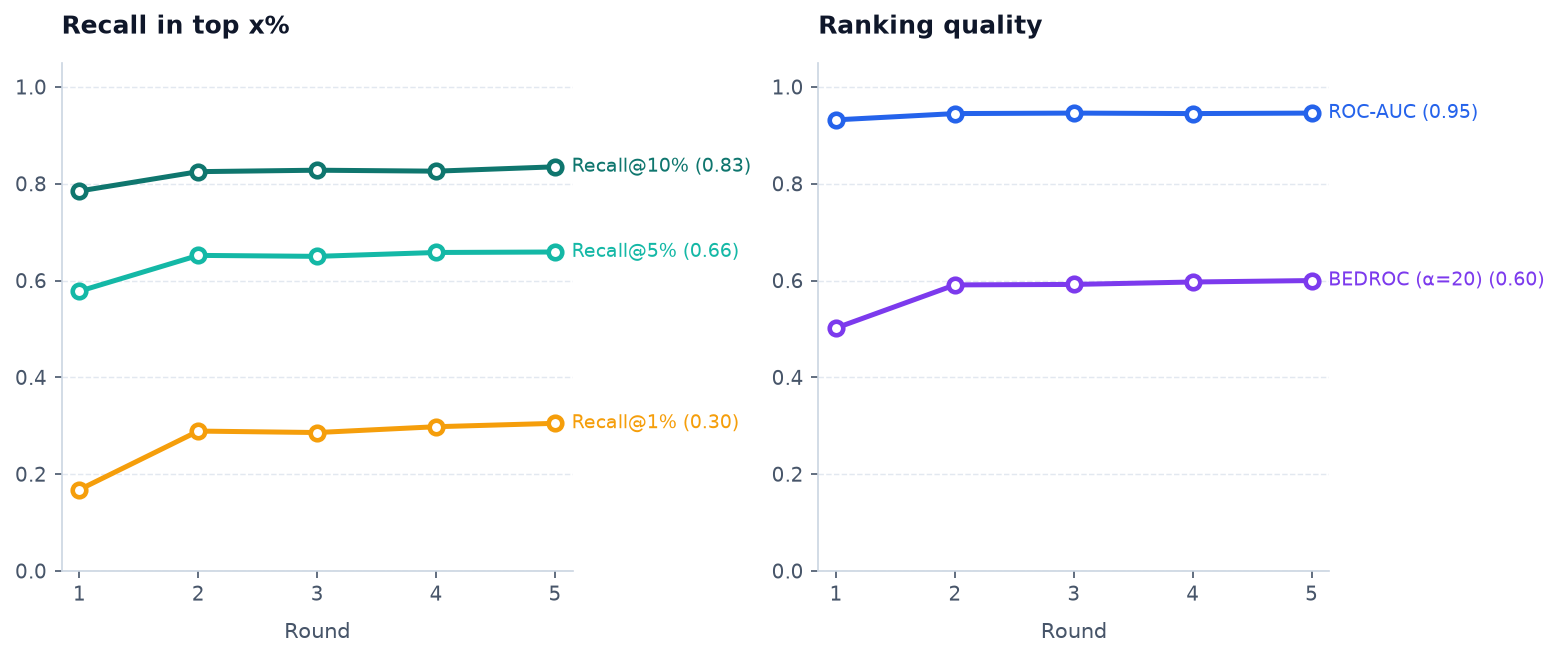

In [5]:
import matplotlib.pyplot as plt
import numpy as np

rounds = np.array([1, 2, 3, 4, 5])

recall_data = {
    "Recall@10%": ([0.785, 0.825, 0.828, 0.826, 0.835], "#0f766e"),  # Deep teal
    "Recall@5%": ([0.578, 0.652, 0.650, 0.658, 0.659], "#14b8a6"),  # Medium teal
    "Recall@1%": ([0.168, 0.289, 0.286, 0.298, 0.305], "#f59e0b"),  # Amber callout
}

ranking_data = {
    "ROC-AUC": ([0.932, 0.945, 0.946, 0.945, 0.946], "#2563eb"),  # Royal blue
    "BEDROC (α=20)": ([0.502, 0.591, 0.592, 0.597, 0.600], "#7c3aed"),  # Violet
}

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), dpi=150)


def style_panel(ax, title, series_dict):
    for label, (vals, color) in series_dict.items():
        ax.plot(
            rounds,
            vals,
            color=color,
            linewidth=2.4,
            marker="o",
            markersize=6.5,
            markerfacecolor="white",
            markeredgewidth=2.2,
            zorder=3,
        )
        ax.annotate(
            f"{label} ({vals[-1]:.2f})",
            xy=(rounds[-1], vals[-1]),
            xytext=(8, 0),
            textcoords="offset points",
            va="center",
            fontsize=9,
            fontweight="medium",
            color=color,
        )

    ax.set_title(
        title, fontsize=12, fontweight="bold", loc="left", pad=14, color="#0f172a"
    )
    ax.set_xlabel("Round", fontsize=10, color="#475569", labelpad=8)
    ax.set_xticks(rounds)
    ax.set_xlim(0.85, 5.15)
    ax.set_ylim(0, 1.05)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#cbd5e1")
    ax.spines["bottom"].set_color("#cbd5e1")
    ax.yaxis.grid(True, linestyle="--", linewidth=0.7, color="#e2e8f0", zorder=0)
    ax.xaxis.grid(False)
    ax.tick_params(colors="#475569", labelsize=9.5)


style_panel(axes[0], "Recall in top x%", recall_data)
style_panel(axes[1], "Ranking quality", ranking_data)

plt.subplots_adjust(wspace=0.48, right=0.86)
plt.show()

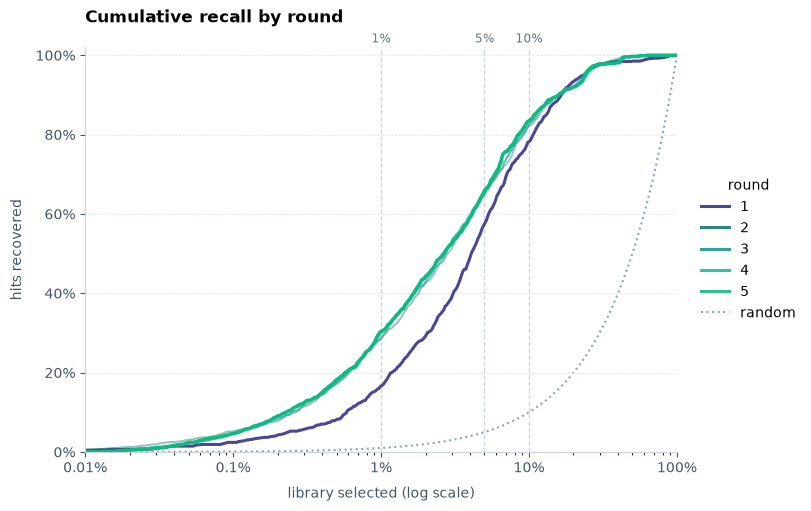

In [11]:
plot_gain_curves(curves)